# Question 3

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
df = pd.read_csv('recipe_id_ingredient_name.csv').dropna()
df['ingredient_name'] = df['ingredient_name'].str.strip().str.lower()
df = df.drop_duplicates()
recipes = {rid: sorted(set(g)) for rid, g in df.groupby('recipe_id')['ingredient_name']}

rng = np.random.default_rng(42)
ingredients = np.array(sorted(df['ingredient_name'].unique()))
M = len(ingredients)
orig_sizes = np.array([len(r) for r in recipes.values()])
N = len(orig_sizes)
max_size = orig_sizes.max()
sizes_axis = np.arange(1, max_size + 1)

def size_dist(sizes):
    """fraction of recipes for each recipe size 1..max_size"""
    c = np.bincount(sizes, minlength=max_size + 1)[1:]
    return c / c.sum()

def style(ax, title):
    ax.set_xlabel('Recipe size (number of ingredients)', fontsize=12)
    ax.set_ylabel('Fraction of recipes', fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.set_xticks(np.arange(0, max_size + 1, 5))
    ax.tick_params(labelsize=11)

idx = {ing: n for n, ing in enumerate(ingredients)}
orig_freq = np.zeros(M)
for r in recipes.values():
    for ing in r:
        orig_freq[idx[ing]] += 1
prob = orig_freq / orig_freq.sum()

## 3(a) Create 10 sets of random cuisines and plot their recipe size distribution

In [2]:
N_SETS = 10
def random_cuisine():
    return [rng.choice(M, size=k, replace=False, p=prob) for k in orig_sizes]

random_cuisines = [random_cuisine() for _ in range(N_SETS)]
print(len(random_cuisines), 'random cuisines of', len(random_cuisines[0]), 'recipes each')

10 random cuisines of 9999 recipes each


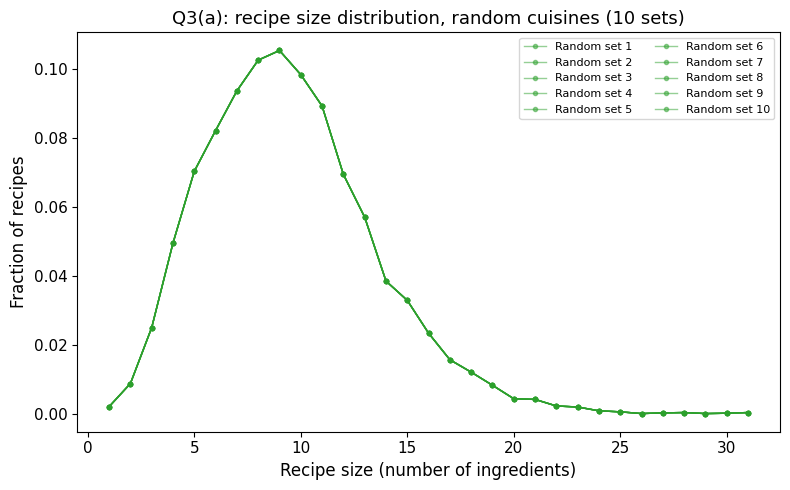

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, c in enumerate(random_cuisines):
    ax.plot(sizes_axis, size_dist(np.array([len(r) for r in c])), '-o', ms=3, color='tab:green', alpha=0.5, lw=1,
            label=f'Random set {i+1}')
style(ax, 'Q3(a): recipe size distribution, random cuisines (10 sets)')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig('outputs/Q3a_size_distribution.png', dpi=150); plt.show()

## 3(b) Frequency-rank distribution

In [4]:
def freq_rank(counts):
    f = np.sort(counts[counts > 0])[::-1] / N         
    return np.arange(1, len(f) + 1), f

def style_fr(ax, title):
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Ingredient rank', fontsize=12)
    ax.set_ylabel('Frequency (fraction of recipes)', fontsize=12)
    ax.set_title(title, fontsize=13); ax.tick_params(labelsize=11)

random_counts = [np.bincount(np.concatenate(c), minlength=M) for c in random_cuisines]

### Original cuisine

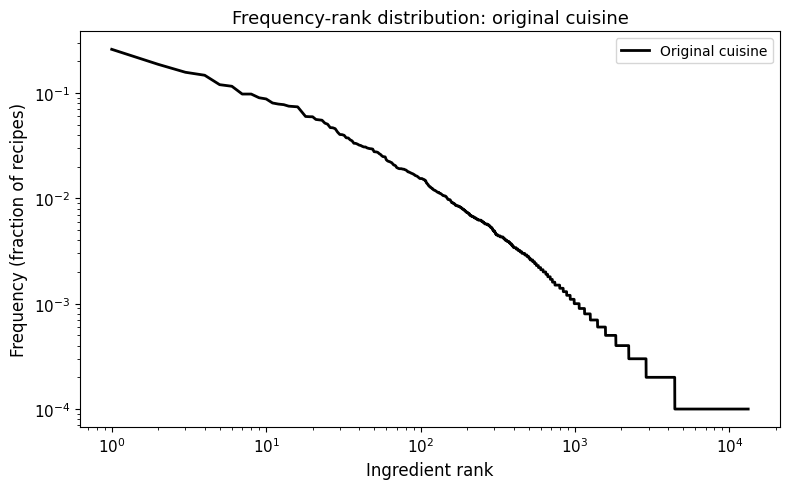

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(*freq_rank(orig_freq), 'k-', lw=2, label='Original cuisine')
style_fr(ax, 'Frequency-rank distribution: original cuisine')
ax.legend(); plt.tight_layout()
plt.savefig('outputs/Q3b_original_frequency_rank.png', dpi=150); plt.show()

### Random cuisines (10 sets)

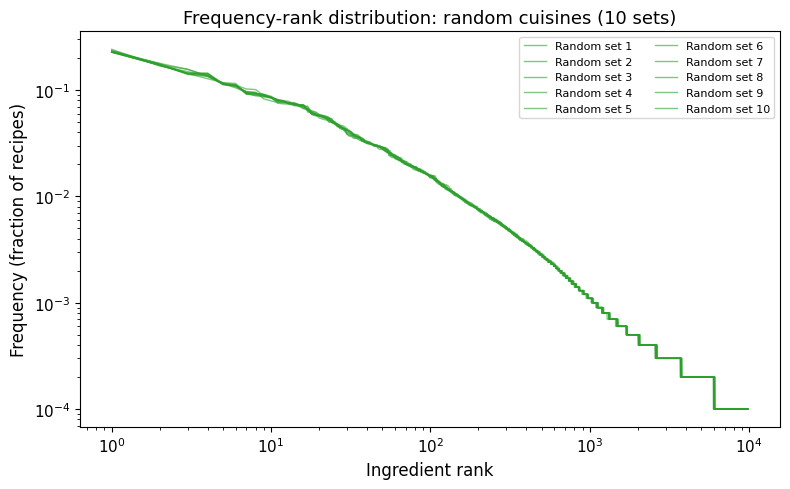

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, cnt in enumerate(random_counts):
    ax.plot(*freq_rank(cnt), color='tab:green', alpha=0.6, lw=1, label=f'Random set {i+1}')
style_fr(ax, 'Frequency-rank distribution: random cuisines (10 sets)')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig('outputs/Q3b_random_frequency_rank.png', dpi=150); plt.show()